# TP3 - Procesamiento del Lenguaje Natural (NLP)
**Inteligencia Artificial y Neurociencias**

**Leoni, Petra - Mendez, Agustín - Pizi, Lucía - Siles, Milagros**

## 5. Evaluación comparativa

En esta parte se comparan los tres enfoques evaluados en las partes anteriores, sobre **el mismo conjunto de test** y con la misma métrica:

| Enfoque | Parte | Modelos que se comparan |
|---|---|---|
| Clásico (ML tradicional) | 2 | Baseline (TF-IDF de unigramas + LogReg) y modelo final elegido |
| Encoder preentrenado | 3 | BETO congelado + LogReg y BETO con *fine-tuning* (3 semillas) |
| LLM generativo | 4 | Zero-shot y few-shot (3 selecciones de ejemplos) |

La comparación busca responder la pregunta central del TP: **¿cuándo conviene utilizar técnicas tradicionales de Machine Learning, modelos preentrenados o LLMs para esta tarea?** Por eso no se mira solo el desempeño, sino también su incertidumbre, los costos (entrenamiento, inferencia, memoria, tamaño) y el tipo de errores de cada enfoque.

**Este notebook no entrena ni ejecuta ningún modelo:** lee los archivos generados por las partes 1 a 4, así que corre en CPU en pocos segundos.

| Archivo | Lo genera | Se usa para |
|---|---|---|
| `splits_tp3.csv` | Parte 1 | Descripción de los conjuntos |
| `resultados_parteN_test.csv` (N = 2, 3, 4) | Partes 2–4 | Métricas, tiempos, memoria y tamaño en test |
| `predicciones_parteN_test.csv` | Partes 2–4 | Intervalos de confianza, matrices de confusión, análisis por comentario |
| `resultados_parteN_val.csv` | Partes 2–4 | Costo y alcance de la exploración en validación |

### 5.0. Configuración

In [ ]:
!pip -q install datasets

In [2]:
import os
import re
import textwrap
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

import sklearn
from sklearn.metrics import (f1_score, accuracy_score, cohen_kappa_score,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
CLASES = ["favor", "against", "neutral"]   # mismo orden que en las partes 1 a 4
N_BOOTSTRAP = 2000

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

COLORES = {"Clásico": "#4C72B0", "Encoder": "#DD8452", "LLM": "#55A868", "Referencia": "#8C8C8C"}

print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)

C:\Users\Agustin\AppData\Local\Temp\claude\937b760f39f78778\83c89cdf-7acf-4294-bdc7-5ab787adf7b7\scratchpad\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.14.6 | pandas: 3.1.1 | scikit-learn: 1.9.1


In [3]:
ARCHIVOS = ["splits_tp3.csv",
            "resultados_parte2_test.csv", "predicciones_parte2_test.csv", "resultados_parte2_val.csv",
            "resultados_parte3_test.csv", "predicciones_parte3_test.csv", "resultados_parte3_val.csv",
            "resultados_parte4_test.csv", "predicciones_parte4_test.csv", "resultados_parte4_val.csv"]

faltantes = [f for f in ARCHIVOS if not os.path.exists(f)]
if faltantes:
    try:   # en Colab se pueden subir los archivos que falten
        from google.colab import files
        print("Faltan archivos, subilos:", faltantes)
        files.upload()
    except ImportError:
        pass
faltantes = [f for f in ARCHIVOS if not os.path.exists(f)]
assert not faltantes, f"Faltan archivos generados por las partes anteriores: {faltantes}"
print("Todos los archivos de resultados están disponibles.")

Todos los archivos de resultados están disponibles.


### 5.1. Conjuntos de entrenamiento, validación y test

Los conjuntos se definieron una única vez en la parte 1 (`splits_tp3.csv`) y se usaron sin cambios en todas las partes:

- **Split agrupado por propuesta** (`target`): todos los comentarios de una misma propuesta quedan en el mismo conjunto, para que el test mida la generalización a propuestas nuevas (con un split aleatorio, 224 de las 226 propuestas de test también aparecían en train).
- Las propuestas con más de 25 comentarios van siempre a train, para que ninguna propuesta domine la evaluación.
- Proporciones ≈70/15/15, con distribuciones de clase similares en los tres conjuntos.
- Se excluyen los 150 comentarios sin mayoría entre anotadores (no tienen `majority_label`).

Se reconstruye el dataset para describir los conjuntos y recuperar el nivel de acuerdo entre anotadores de cada comentario de test (se usa en 5.7).

In [4]:
dataset = load_dataset("SINAI/ALIA-es-discriminative-stance-detection")
df = dataset["train"].to_pandas()

cols_anotadores = ["annotation_1", "annotation_2", "annotation_3"]
df_modelado = df[df["majority_label"].isin(CLASES)].copy().reset_index(drop=True)
df_modelado["label"] = df_modelado["majority_label"]
df_modelado["id"] = df_modelado["id"].astype(str)
df_modelado["max_acuerdo"] = df_modelado[cols_anotadores].apply(lambda f: f.value_counts().max(), axis=1)
df_modelado["nivel_acuerdo"] = df_modelado["max_acuerdo"].map({3: "Total (3/3)", 2: "Parcial (2/3)"})

splits = pd.read_csv("splits_tp3.csv", dtype={"id": str})
df_modelado = df_modelado.merge(splits, on="id", how="left", validate="one_to_one")
assert df_modelado["split"].notna().all(), "Hay comentarios sin split asignado"
assert len(df_modelado) == 2850

orden = ["train", "val", "test"]
resumen_splits = pd.DataFrame({
    "comentarios": df_modelado["split"].value_counts(),
    "% del total": df_modelado["split"].value_counts(normalize=True) * 100,
    "propuestas": df_modelado.groupby("split")["target"].nunique(),
    "acuerdo total (3/3) %": df_modelado.groupby("split")["max_acuerdo"].apply(lambda s: (s == 3).mean() * 100),
}).loc[orden]
dist = pd.crosstab(df_modelado["split"], df_modelado["label"], normalize="index").loc[orden, CLASES] * 100
resumen_splits = resumen_splits.join(dist.add_prefix("% "))
display(resumen_splits.round(1))

# Ninguna propuesta aparece en más de un conjunto
por_split = {s: set(df_modelado.loc[df_modelado["split"] == s, "target"]) for s in orden}
assert not (por_split["train"] & por_split["val"]) and not (por_split["train"] & por_split["test"]) \
    and not (por_split["val"] & por_split["test"])
print("Ninguna propuesta se comparte entre conjuntos.")

test_df = df_modelado[df_modelado["split"] == "test"].set_index("id")

,comentarios,% del total,propuestas,acuerdo total (3/3) %,% favor,% against,% neutral
split,,,,,,,
train,2019,70.8,242,54.1,62.5,22.0,15.5
val,413,14.5,75,55.7,63.2,21.1,15.7
test,418,14.7,70,51.7,61.5,22.7,15.8


Ninguna propuesta se comparte entre conjuntos.


**Uso de cada conjunto en cada enfoque.** En ningún caso el test se usó para tomar decisiones: cada parte lo evaluó una única vez, al final, con la configuración ya elegida.

| Enfoque | Train | Validación | Test |
|---|---|---|---|
| Clásico (parte 2) | Ajuste de los modelos | Selección de preprocesamiento, features, modelo e hiperparámetros (+ validación cruzada agrupada sobre train+val para la elección final). El modelo final se reentrena en train+val | Evaluación final |
| Encoder (parte 3) | Ajuste de la LogReg (congelado) y *fine-tuning* | Selección de pooling, `C`, learning rate, épocas, longitud máxima y del mejor checkpoint (*early stopping*) | Evaluación final (3 semillas) |
| LLM (parte 4) | Sin ajustar pesos: fuente de los ejemplos del *few-shot* y de 200 comentarios para calibrar los sesgos de las etiquetas (`sesgo_train`) | Selección de la instrucción, de la cantidad y forma de elegir los ejemplos y del método de calibración | Evaluación final (zero-shot y 3 selecciones de ejemplos) |

**Métrica principal:** Macro-F1 respecto de `majority_label` con las tres clases. Todos los enfoques producen una etiqueta por comentario, por lo que sus predicciones son directamente comparables.

### 5.2. Carga y unificación de resultados

Cada parte guardó sus resultados con columnas algo distintas. Se arma una única tabla con un modelo representativo por fila:

- **Clásico:** baseline y modelo final (reentrenado en train+val).
- **Encoder:** BETO congelado + LogReg y BETO con *fine-tuning* (media de 3 semillas).
- **LLM:** zero-shot y few-shot (media de 3 selecciones de ejemplos).

Para los modelos con varias corridas (semillas o selecciones de ejemplos) se reporta la media de las métricas y el desvío entre corridas, y se conservan las predicciones de todas las corridas.

Los nombres de las filas se detectan por patrón (no están fijos), así que la tabla se actualiza sola si se vuelve a ejecutar alguna parte con otra configuración.

In [5]:
p2 = pd.read_csv("resultados_parte2_test.csv", index_col=0)
p3 = pd.read_csv("resultados_parte3_test.csv", index_col=0)
p4 = pd.read_csv("resultados_parte4_test.csv", index_col=0)

pred2 = pd.read_csv("predicciones_parte2_test.csv", dtype={"id": str}).set_index("id")
pred3 = pd.read_csv("predicciones_parte3_test.csv", dtype={"id": str}).set_index("id")
pred4 = pd.read_csv("predicciones_parte4_test.csv", dtype={"id": str}).set_index("id")

# Las tres partes deben haber evaluado exactamente los mismos comentarios con las mismas etiquetas
for nombre, p in [("parte 2", pred2), ("parte 3", pred3), ("parte 4", pred4)]:
    assert set(p.index) == set(test_df.index), f"Los comentarios de test de la {nombre} no coinciden"
    assert (p["label"] == test_df.loc[p.index, "label"]).all(), f"Las etiquetas de la {nombre} no coinciden"
preds = pd.concat([pred2.drop(columns="label"), pred3.drop(columns="label"), pred4.drop(columns="label")],
                  axis=1).loc[test_df.index]
y_test = test_df["label"].to_numpy()
print(f"Test: {len(y_test)} comentarios, mismos ids y etiquetas en las partes 2, 3 y 4.")
print("Columnas de predicción disponibles:", list(preds.columns))

Test: 418 comentarios, mismos ids y etiquetas en las partes 2, 3 y 4.
Columnas de predicción disponibles: ['pred_baseline', 'pred_final', 'pred_sin_finetuning', 'pred_finetuning_seed42', 'pred_finetuning_seed43', 'pred_finetuning_seed44', 'pred_zero_shot', 'pred_few_shot_n12_seed0', 'pred_few_shot_n12_seed1', 'pred_few_shot_n12_seed2']


In [6]:
METRICAS = ["macro_f1", "accuracy", "f1_favor", "f1_against", "f1_neutral"]


def gpu_de(tabla):
    return f"GPU ({tabla['gpu'].dropna().iloc[0]})" if "gpu" in tabla and tabla["gpu"].notna().any() else "GPU"


def fila_desvio(tabla, nombre_media):
    # Para '... (media de 3 semillas)' busca '... (desvío entre semillas)'
    prefijo = nombre_media.split(" (media de")[0]
    cand = [m for m in tabla.index if m.startswith(prefijo) and "desvío" in m]
    return tabla.loc[cand[0]] if cand else None


filas = []

def agregar(enfoque, nombre, fila, cols_pred, hardware, desvio=None, extra=None):
    filas.append({
        "enfoque": enfoque, "modelo": nombre,
        **{m: fila[m] for m in METRICAS},
        "macro_f1_desvio_corridas": desvio["macro_f1"] if desvio is not None else np.nan,
        "n_corridas": len(cols_pred),
        "t_train_s": fila.get("t_train_s", np.nan),
        "t_inf_por_1000_s": fila["t_inf_por_1000_s"],
        "vram_pico_GB": fila.get("vram_pico_GB", np.nan),
        "tamaño_modelo_MB": fila["tamaño_modelo_MB"],
        "hardware": hardware,
        "cols_pred": cols_pred,
        **(extra or {}),
    })

# --- Parte 2: clásico (medido en CPU) ---
p2["t_inf_por_1000_s"] = p2["t_inf_por_1000_ms"] / 1000
nombre_base = next(m for m in p2.index if m.startswith("Baseline"))
nombre_final = next((m for m in p2.index if m.endswith("(train+val)")), p2.index[-1])
detalle_final = re.sub(r"^Elegido:\s*", "", nombre_final)
agregar("Clásico", "Clásico: baseline (TF-IDF + LogReg)", p2.loc[nombre_base], ["pred_baseline"], "CPU")
agregar("Clásico", f"Clásico: final, {detalle_final}", p2.loc[nombre_final], ["pred_final"], "CPU")

# --- Parte 3: encoder ---
nombre_sin_ft = next(m for m in p3.index if m.startswith("BETO sin fine-tuning"))
nombre_ft = next(m for m in p3.index if "fine-tuning (media de" in m)
cols_ft = [c for c in preds.columns if c.startswith("pred_finetuning_seed")]
agregar("Encoder", "Encoder: BETO congelado + LogReg", p3.loc[nombre_sin_ft], ["pred_sin_finetuning"], gpu_de(p3))
agregar("Encoder", f"Encoder: BETO fine-tuning ({len(cols_ft)} semillas)", p3.loc[nombre_ft], cols_ft, gpu_de(p3),
        desvio=fila_desvio(p3, nombre_ft))

# --- Parte 4: LLM (puede haber más de un LLM o configuración) ---
nombres_zs = [m for m in p4.index if "zero-shot" in m]
cols_zs = [c for c in preds.columns if c.startswith("pred_zero_shot")]
assert len(nombres_zs) == len(cols_zs), "No coincide la cantidad de modelos zero-shot entre resultados y predicciones"
for nombre, col in zip(nombres_zs, cols_zs):
    agregar("LLM", f"LLM: {nombre}", p4.loc[nombre], [col], gpu_de(p4))

nombres_fs = [m for m in p4.index if "few-shot" in m and "(media de" in m]
for nombre in nombres_fs:
    letra, k = re.search(r" ([kn])=(\d+)", nombre).groups()   # "k=12" o "n=12" según la versión de la etapa 4
    cols_fs = [c for c in preds.columns if c.startswith(f"pred_few_shot_{letra}{k}_")]
    assert cols_fs, f"No se encontraron predicciones para {nombre}"
    agregar("LLM", f"LLM: {nombre.split(' (media de')[0]} ({len(cols_fs)} selecciones)", p4.loc[nombre], cols_fs,
            gpu_de(p4), desvio=fila_desvio(p4, nombre))

comp = pd.DataFrame(filas).set_index("modelo")
CORTO = {m: m.split(": ", 1)[1] for m in comp.index}   # nombre sin el prefijo del enfoque, para los gráficos
COSTO_CARGA_LLM_S = p4["t_carga_modelo_s"].dropna().iloc[0] if "t_carga_modelo_s" in p4 else np.nan
print(f"{len(comp)} modelos a comparar.")

6 modelos a comparar.


**Control de consistencia.** Se recalculan las métricas a partir de las predicciones guardadas y se comparan con las reportadas por cada parte (para los modelos con varias corridas, la media entre corridas).

In [7]:
def metricas(y, y_pred):
    f1s = f1_score(y, y_pred, labels=CLASES, average=None, zero_division=0)
    return {"macro_f1": f1s.mean(), "accuracy": accuracy_score(y, y_pred),
            **{f"f1_{c}": v for c, v in zip(CLASES, f1s)}}

for modelo, fila in comp.iterrows():
    recalc = pd.DataFrame([metricas(y_test, preds[c]) for c in fila["cols_pred"]]).mean()
    for m in METRICAS:
        assert abs(recalc[m] - fila[m]) < 1e-6, f"{modelo}: {m} reportado {fila[m]:.4f} vs. recalculado {recalc[m]:.4f}"
print("Las métricas recalculadas coinciden con las reportadas por cada parte.")

Las métricas recalculadas coinciden con las reportadas por cada parte.


### 5.3. Tabla comparativa: desempeño y costos

Como referencia mínima se agrega un clasificador trivial que siempre predice la clase mayoritaria (*favor*). Un clasificador que predice al azar respetando las proporciones de clase obtiene, en promedio, un Macro-F1 ≈ 1/3 (el F1 esperado de cada clase es igual a su proporción).

**Cómo leer los costos:**
- `t_train_s`: tiempo de entrenamiento de la configuración final (sin contar la exploración, que se analiza en 5.6). Para BETO congelado incluye extraer los embeddings de train. El LLM no se entrena: en su caso es el tiempo de calibración (puntuar 200 comentarios de train para ajustar los sesgos de *against* y *neutral*).
- `t_inf_por_1000_s`: segundos para clasificar 1.000 comentarios.
- Los tiempos del enfoque clásico se midieron en **CPU** (2 núcleos de Colab) y los del encoder y el LLM en **GPU** (T4). Correr el encoder o el LLM en CPU sería uno o dos órdenes de magnitud más lento, así que la comparación de tiempos favorece a los modelos grandes.

In [8]:
referencias = {"Referencia: siempre 'favor'": np.full(len(y_test), "favor", dtype=object)}
for nombre, y_pred in referencias.items():
    preds[nombre] = y_pred

ref = pd.DataFrame([{"modelo": n, "enfoque": "Referencia", **metricas(y_test, p), "n_corridas": 1,
                     "t_train_s": 0.0, "t_inf_por_1000_s": np.nan, "tamaño_modelo_MB": 0.0, "hardware": "—",
                     "cols_pred": [n]} for n, p in referencias.items()]).set_index("modelo")
comp_total = pd.concat([ref, comp])
MACRO_F1_MAYORITARIA = ref.loc["Referencia: siempre 'favor'", "macro_f1"]

COLS_TABLA = ["enfoque", "macro_f1", "macro_f1_desvio_corridas", "accuracy", "f1_favor", "f1_against", "f1_neutral",
              "t_train_s", "t_inf_por_1000_s", "vram_pico_GB", "tamaño_modelo_MB", "hardware"]
tabla = comp_total[COLS_TABLA].rename(columns={"macro_f1_desvio_corridas": "macro_f1_desvío"})
display(tabla.round({"macro_f1": 3, "macro_f1_desvío": 3, "accuracy": 3, "f1_favor": 3, "f1_against": 3,
                     "f1_neutral": 3, "t_train_s": 1, "t_inf_por_1000_s": 2, "vram_pico_GB": 2,
                     "tamaño_modelo_MB": 1}).astype(object).where(lambda d: d.notna(), "—"))
if not np.isnan(COSTO_CARGA_LLM_S):
    print(f"Nota: cargar el LLM en memoria toma además ≈{COSTO_CARGA_LLM_S:.0f} s (costo fijo, no incluido en la tabla).")

,enfoque,macro_f1,macro_f1_desvío,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_inf_por_1000_s,vram_pico_GB,tamaño_modelo_MB,hardware
modelo,,,,,,,,,,,,
Referencia: siempre 'favor',Referencia,0.254,—,0.615,0.761,0.0,0.0,0.0,—,—,0.0,—
Clásico: baseline (TF-IDF + LogReg),Clásico,0.309,—,0.629,0.772,0.095,0.059,0.9,0.08,—,0.6,CPU
"Clásico: final, LogReg C=1 (train+val)",Clásico,0.435,—,0.529,0.667,0.346,0.292,3.6,0.65,—,1.3,CPU
Encoder: BETO congelado + LogReg,Encoder,0.458,—,0.502,0.604,0.459,0.311,7.6,3.5,2.05,439.4,GPU (Tesla T4)
Encoder: BETO fine-tuning (3 semillas),Encoder,0.495,0.017,0.611,0.731,0.464,0.29,72.4,1.18,2.45,439.4,GPU (Tesla T4)
"LLM: Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)",LLM,0.537,—,0.6,0.721,0.485,0.405,8.2,37.24,4.73,3087.4,GPU (Tesla T4)
LLM: Qwen2.5-1.5B few-shot n=12 (3 selecciones),LLM,0.53,0.018,0.6,0.716,0.481,0.392,75.4,371.54,4.73,3087.4,GPU (Tesla T4)


Nota: cargar el LLM en memoria toma además ≈58 s (costo fijo, no incluido en la tabla).


### 5.4. ¿Las diferencias son significativas? Intervalos de confianza por *bootstrap*

El test tiene solo 418 comentarios (≈60 *neutral* y ≈90 *against*), así que unos pocos aciertos más o menos mueven el Macro-F1 varios puntos. Para saber qué diferencias son confiables se usa **bootstrap**: se remuestrean los comentarios de test con reposición 2.000 veces y se recalcula el Macro-F1 en cada muestra.

- **IC 95% de cada modelo:** percentiles 2,5 y 97,5 del Macro-F1 remuestreado. Para los modelos con varias corridas, en cada muestra se promedia el Macro-F1 de todas las corridas, así que el intervalo incluye la incertidumbre por el test pero no la variabilidad entre semillas (que se reporta aparte).
- **Bootstrap pareado:** para comparar dos modelos se usan *las mismas* muestras para ambos y se mira la distribución de la diferencia. Es más sensible que comparar los intervalos por separado, porque los dos modelos se evalúan sobre los mismos comentarios.

In [9]:
lab2id = {c: i for i, c in enumerate(CLASES)}
y_id = np.array([lab2id[c] for c in y_test])
idx_boot = np.random.RandomState(SEED).randint(0, len(y_id), size=(N_BOOTSTRAP, len(y_id)))
Y_B = y_id[idx_boot]


def macro_f1_boot(y_pred_ids):
    # Macro-F1 de cada muestra bootstrap, vectorizado
    P_B = y_pred_ids[idx_boot]
    f1s = []
    for k in range(len(CLASES)):
        tp = ((P_B == k) & (Y_B == k)).sum(1)
        fp = ((P_B == k) & (Y_B != k)).sum(1)
        fn = ((P_B != k) & (Y_B == k)).sum(1)
        den = 2 * tp + fp + fn
        f1s.append(np.divide(2 * tp, den, out=np.zeros(len(tp), dtype=float), where=den > 0))
    return np.mean(f1s, axis=0)


BOOT = {}
for modelo, fila in comp_total.iterrows():
    BOOT[modelo] = np.mean([macro_f1_boot(np.array([lab2id[c] for c in preds[col]])) for col in fila["cols_pred"]],
                           axis=0)

comp_total["ic95_inf"] = [np.percentile(BOOT[m], 2.5) for m in comp_total.index]
comp_total["ic95_sup"] = [np.percentile(BOOT[m], 97.5) for m in comp_total.index]
display(comp_total[["enfoque", "macro_f1", "ic95_inf", "ic95_sup", "macro_f1_desvio_corridas"]].round(3))

,enfoque,macro_f1,ic95_inf,ic95_sup,macro_f1_desvio_corridas
modelo,,,,,
Referencia: siempre 'favor',Referencia,0.254,0.242,0.265,NaN
Clásico: baseline (TF-IDF + LogReg),Clásico,0.309,0.272,0.351,NaN
"Clásico: final, LogReg C=1 (train+val)",Clásico,0.435,0.384,0.487,NaN
Encoder: BETO congelado + LogReg,Encoder,0.458,0.408,0.507,NaN
Encoder: BETO fine-tuning (3 semillas),Encoder,0.495,0.453,0.541,0.017
"LLM: Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)",LLM,0.537,0.484,0.588,NaN
LLM: Qwen2.5-1.5B few-shot n=12 (3 selecciones),LLM,0.530,0.485,0.575,0.018


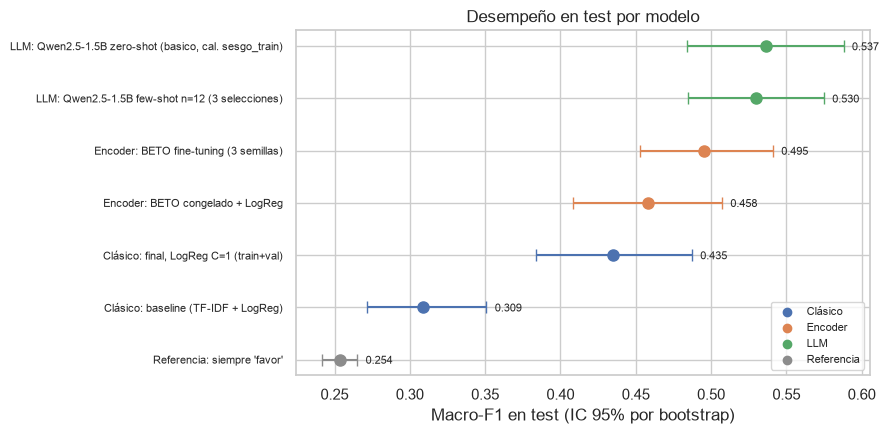

In [10]:
orden_modelos = comp_total.sort_values("macro_f1").index
fig, ax = plt.subplots(figsize=(9, 0.5 * len(orden_modelos) + 1))
for i, m in enumerate(orden_modelos):
    f = comp_total.loc[m]
    ax.errorbar(f["macro_f1"], i, xerr=[[f["macro_f1"] - f["ic95_inf"]], [f["ic95_sup"] - f["macro_f1"]]],
                fmt="o", ms=8, capsize=4, color=COLORES[f["enfoque"]])
    ax.annotate(f"{f['macro_f1']:.3f}", (f["ic95_sup"], i), xytext=(6, -3), textcoords="offset points", fontsize=8)
ax.set_yticks(range(len(orden_modelos))); ax.set_yticklabels(orden_modelos, fontsize=8)
ax.set_xlabel("Macro-F1 en test (IC 95% por bootstrap)")
ax.set_title("Desempeño en test por modelo")
for e, c in COLORES.items():
    ax.scatter([], [], color=c, label=e)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Comparaciones pareadas.** Se compara cada modelo contra el mejor modelo de cada uno de los otros enfoques y contra el baseline clásico. La tabla muestra la diferencia de Macro-F1 (fila − columna), su IC 95% y la proporción de muestras bootstrap en que la fila supera a la columna. Si el intervalo contiene al 0, la diferencia no es concluyente con este tamaño de test.

Mejor modelo de cada enfoque (en test, solo para el análisis; no se usa para elegir nada):
  Clásico: Clásico: final, LogReg C=1 (train+val)
  Encoder: Encoder: BETO fine-tuning (3 semillas)
  LLM: LLM: Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)


vs,Clásico: baseline (TF-IDF + LogReg),"Clásico: final, LogReg C=1 (train+val)",Encoder: BETO fine-tuning (3 semillas),"LLM: Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)"
modelo,,,,
Clásico: baseline (TF-IDF + LogReg),—,"-0.126 [-0.184, -0.066]","-0.186 [-0.238, -0.136]","-0.228 [-0.290, -0.164]"
"Clásico: final, LogReg C=1 (train+val)","+0.126 [+0.066, +0.184]",—,"-0.061 [-0.116, -0.004]","-0.102 [-0.165, -0.037]"
Encoder: BETO congelado + LogReg,"+0.149 [+0.091, +0.209]","+0.023 [-0.032, +0.079]","-0.037 [-0.089, +0.014]","-0.079 [-0.146, -0.016]"
Encoder: BETO fine-tuning (3 semillas),"+0.186 [+0.136, +0.238]","+0.061 [+0.004, +0.116]",—,"-0.041 [-0.098, +0.019]"
"LLM: Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)","+0.228 [+0.164, +0.290]","+0.102 [+0.037, +0.165]","+0.041 [-0.019, +0.098]",—
LLM: Qwen2.5-1.5B few-shot n=12 (3 selecciones),"+0.221 [+0.163, +0.275]","+0.095 [+0.034, +0.155]","+0.035 [-0.020, +0.088]","-0.007 [-0.051, +0.036]"


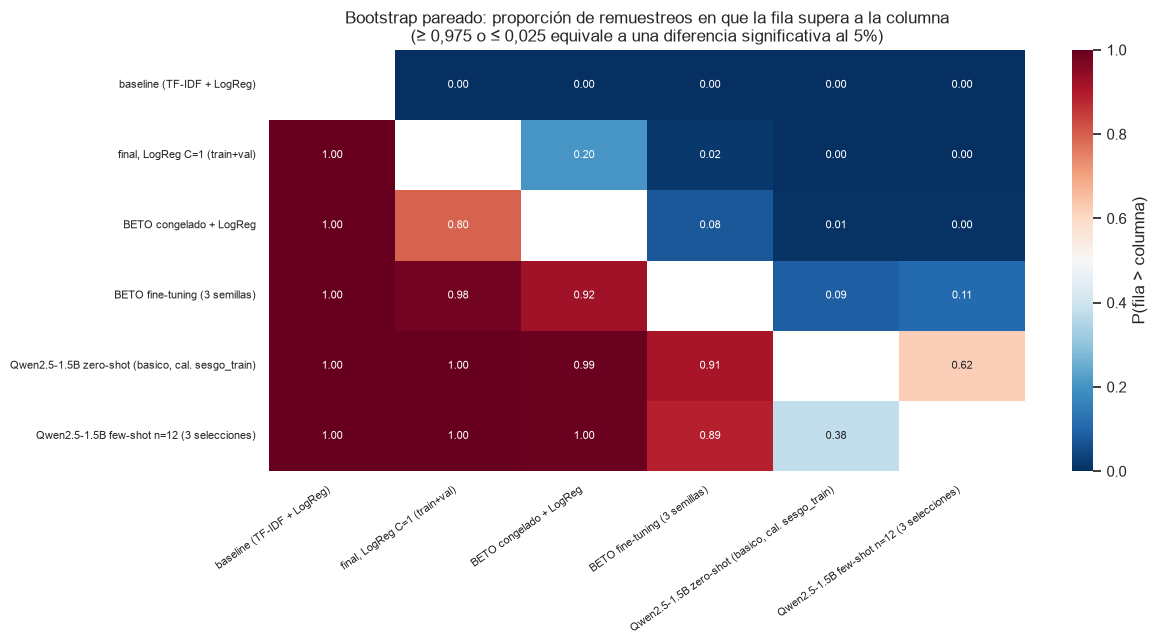

In [11]:
modelos_reales = comp.index.tolist()
mejor_por_enfoque = comp.groupby("enfoque")["macro_f1"].idxmax()
print("Mejor modelo de cada enfoque (en test, solo para el análisis; no se usa para elegir nada):")
for e, m in mejor_por_enfoque.items():
    print(f"  {e}: {m}")

filas_par = []
for a in modelos_reales:
    for b in modelos_reales:
        if a == b:
            continue
        d = BOOT[a] - BOOT[b]
        filas_par.append({"modelo": a, "vs": b, "dif": comp.loc[a, "macro_f1"] - comp.loc[b, "macro_f1"],
                          "ic95_inf": np.percentile(d, 2.5), "ic95_sup": np.percentile(d, 97.5),
                          "P(fila > col)": (d > 0).mean()})
pares = pd.DataFrame(filas_par)

texto = pares.assign(celda=lambda d: d.apply(
    lambda r: f"{r['dif']:+.3f} [{r['ic95_inf']:+.3f}, {r['ic95_sup']:+.3f}]", axis=1))
cols_vs = list(dict.fromkeys([comp.index[0]] + mejor_por_enfoque.tolist()))
display(texto[texto["vs"].isin(cols_vs)].pivot(index="modelo", columns="vs", values="celda")
        .reindex(index=modelos_reales, columns=cols_vs).fillna("—"))

fig, ax = plt.subplots(figsize=(1.4 * len(modelos_reales) + 4, 0.6 * len(modelos_reales) + 3))
matriz = pares.pivot(index="modelo", columns="vs", values="P(fila > col)").reindex(index=modelos_reales,
                                                                                    columns=modelos_reales)
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="RdBu_r", center=0.5, vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "P(fila > columna)"}, annot_kws={"fontsize": 8})
ax.set_xticklabels([CORTO[m] for m in modelos_reales], rotation=35, ha="right", fontsize=8)
ax.set_yticklabels([CORTO[m] for m in modelos_reales], fontsize=8)
ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
ax.set_title("Bootstrap pareado: proporción de remuestreos en que la fila supera a la columna\n"
             "(≥ 0,975 o ≤ 0,025 equivale a una diferencia significativa al 5%)")
plt.tight_layout(); plt.show()

### 5.5. Desempeño por clase y matrices de confusión

El Macro-F1 promedia las tres clases, así que dos modelos con el mismo valor pueden equivocarse de formas muy distintas. Se mira el F1 de cada clase y las matrices de confusión (normalizadas por fila: qué fracción de cada clase real termina en cada predicción). Para los modelos con varias corridas se promedian las matrices de todas las corridas, para no elegir una semilla en particular.

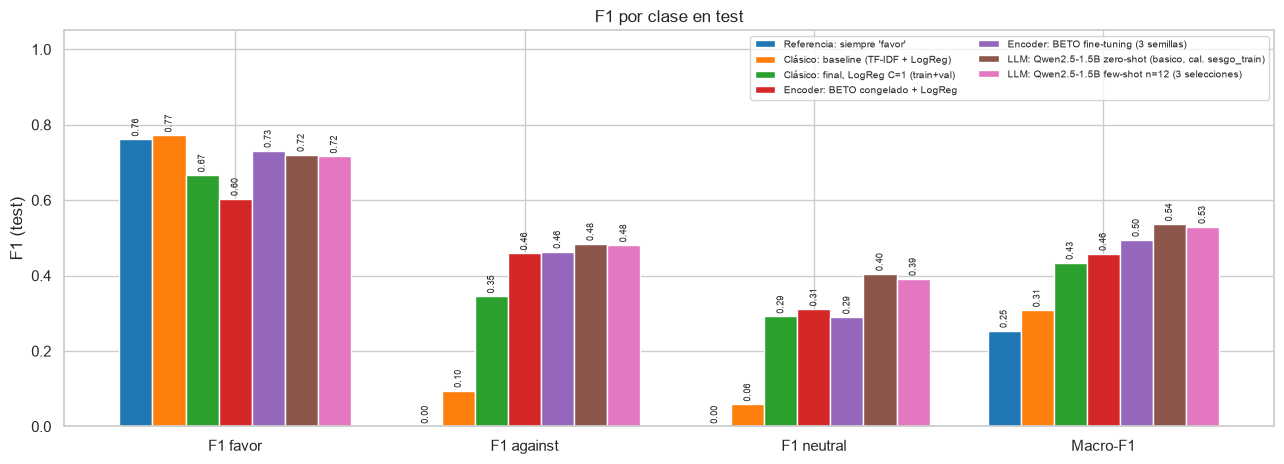

In [12]:
cols_f1 = [f"f1_{c}" for c in CLASES] + ["macro_f1"]
graf = comp_total[cols_f1]
fig, ax = plt.subplots(figsize=(13, 4.8))
ancho = 0.8 / len(graf)
paleta = sns.color_palette("tab10", len(graf))
for i, (m, f) in enumerate(graf.iterrows()):
    pos = np.arange(len(cols_f1)) + (i - (len(graf) - 1) / 2) * ancho
    barras = ax.bar(pos, f.to_numpy(dtype=float), ancho, label=m, color=paleta[i])
    ax.bar_label(barras, fmt="%.2f", fontsize=6.5, rotation=90, padding=2)
ax.set_xticks(range(len(cols_f1))); ax.set_xticklabels(["F1 favor", "F1 against", "F1 neutral", "Macro-F1"])
ax.set_ylim(0, 1.05); ax.set_ylabel("F1 (test)"); ax.set_title("F1 por clase en test")
ax.legend(fontsize=7.5, loc="upper right", ncol=2)
plt.tight_layout(); plt.show()

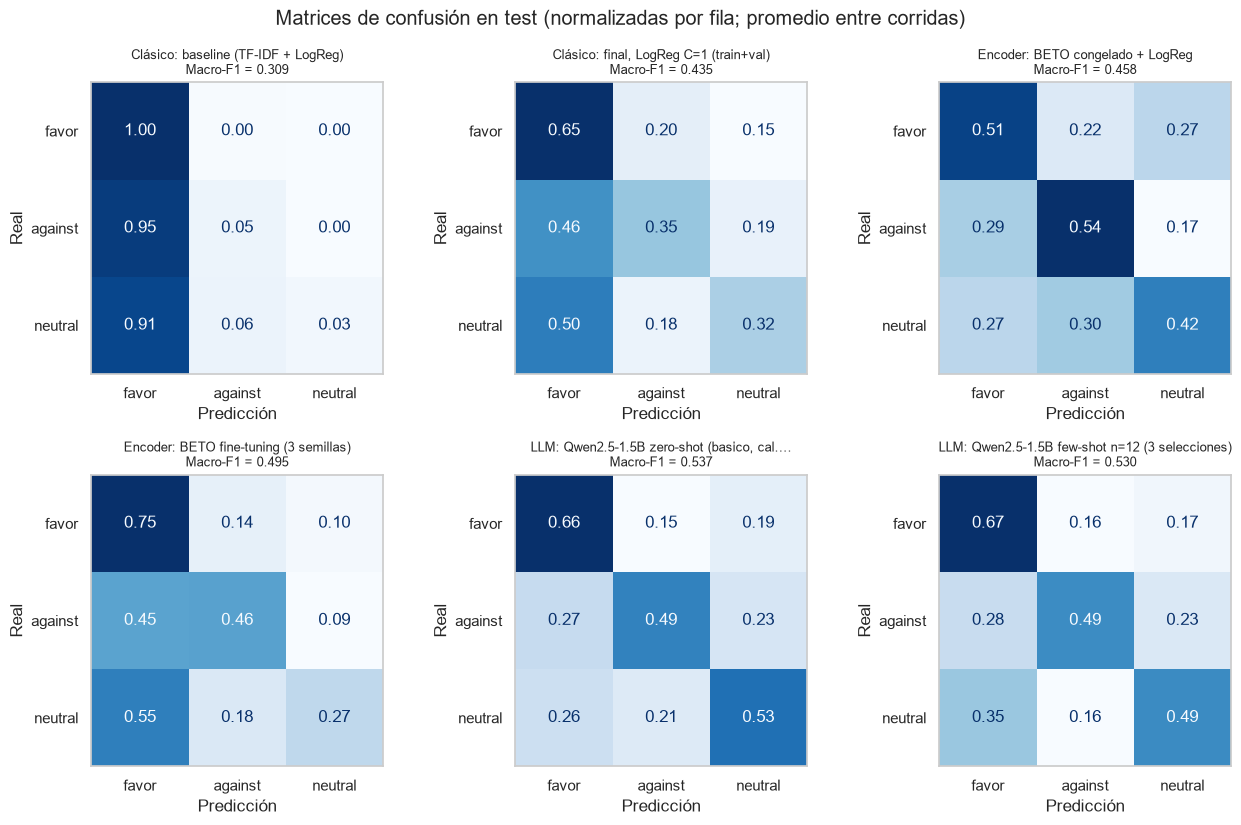

,% predicho favor,% predicho against,% predicho neutral
Clásico: baseline (TF-IDF + LogReg),97.1,2.4,0.5
"Clásico: final, LogReg C=1 (train+val)",58.4,23.0,18.7
Encoder: BETO congelado + LogReg,42.3,30.4,27.3
Encoder: BETO fine-tuning (3 semillas),65.4,22.2,12.4
"LLM: Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)",50.7,23.7,25.6
LLM: Qwen2.5-1.5B few-shot n=12 (3 selecciones),53.1,23.2,23.7
Real (test),61.5,22.7,15.8


In [13]:
fig, axes = plt.subplots(2, int(np.ceil(len(comp) / 2)), figsize=(4.3 * np.ceil(len(comp) / 2), 8.4))
for ax, (m, f) in zip(axes.ravel(), comp.iterrows()):
    cm = np.mean([confusion_matrix(y_test, preds[c], labels=CLASES, normalize="true") for c in f["cols_pred"]], axis=0)
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{f['enfoque']}: {textwrap.shorten(CORTO[m], 48, placeholder='…')}\nMacro-F1 = {f['macro_f1']:.3f}", fontsize=9)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.grid(False)
for ax in axes.ravel()[len(comp):]:
    ax.axis("off")
plt.suptitle("Matrices de confusión en test (normalizadas por fila; promedio entre corridas)")
plt.tight_layout(); plt.show()

# Proporción de cada clase en las predicciones (sesgo de cada modelo hacia alguna etiqueta)
dist_pred = pd.DataFrame({m: pd.concat([preds[c] for c in f["cols_pred"]]).value_counts(normalize=True)
                          .reindex(CLASES).fillna(0) * 100 for m, f in comp.iterrows()}).T
dist_pred.loc["Real (test)"] = pd.Series(y_test).value_counts(normalize=True).reindex(CLASES) * 100
display(dist_pred.round(1).add_prefix("% predicho "))

### 5.6. Desempeño vs. costos

Se relaciona el desempeño con tres tipos de costo:

1. **Costo de inferencia** (por comentario): lo que se paga cada vez que se usa el modelo. Es el costo que domina si el sistema se usa sobre muchos comentarios.
2. **Costo de entrenamiento** de la configuración final y **recursos** (tamaño del modelo, VRAM).
3. **Costo de la exploración:** cuántas configuraciones se probaron en validación y cuánto tiempo de cómputo llevó elegir la configuración final. Es una cota inferior (no incluye, por ejemplo, la validación cruzada de la parte 2 ni la extracción de embeddings de la parte 3).

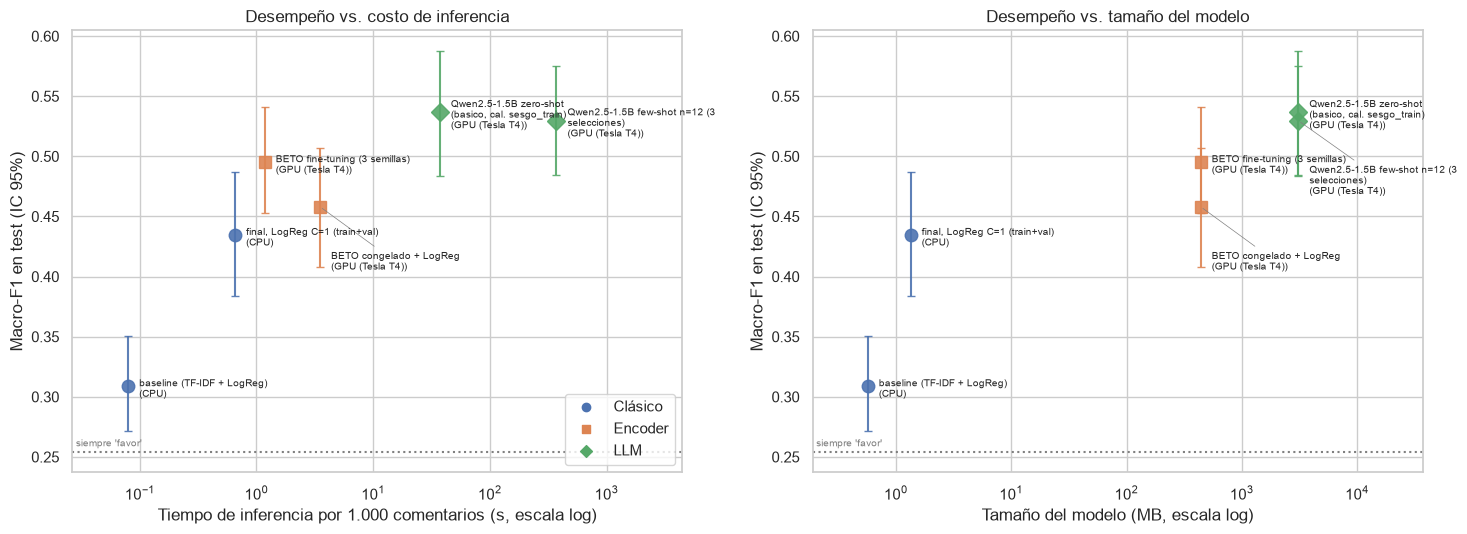

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
marcadores = {"Clásico": "o", "Encoder": "s", "LLM": "D"}

for ax, x_col, x_lab in [(axes[0], "t_inf_por_1000_s", "Tiempo de inferencia por 1.000 comentarios (s, escala log)"),
                         (axes[1], "tamaño_modelo_MB", "Tamaño del modelo (MB, escala log)")]:
    ubicadas = []   # etiquetas ya puestas: (log10 x, y, desplazamiento vertical), para que no se superpongan
    for m, f in comp.sort_values("macro_f1", ascending=False).iterrows():
        yerr = [[f["macro_f1"] - comp_total.loc[m, "ic95_inf"]], [comp_total.loc[m, "ic95_sup"] - f["macro_f1"]]]
        ax.errorbar(f[x_col], f["macro_f1"], yerr=yerr, fmt=marcadores[f["enfoque"]], ms=9, capsize=3,
                    color=COLORES[f["enfoque"]], alpha=0.9)
        lx = np.log10(f[x_col])
        dy = -2
        while any(abs(lx - x0) < 0.6 and abs(f["macro_f1"] - y0) < 0.04 and dy == d0 for x0, y0, d0 in ubicadas):
            dy -= 30
        ubicadas.append((lx, f["macro_f1"], dy))
        etiqueta = textwrap.fill(CORTO[m], 30)
        ax.annotate(f"{etiqueta}\n({f['hardware']})", (f[x_col], f["macro_f1"]), textcoords="offset points",
                    xytext=(8, dy), fontsize=7, va="top" if dy < -2 else "center",
                    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5) if dy < -2 else None)
    ax.set_xscale("log"); ax.set_xlabel(x_lab); ax.set_ylabel("Macro-F1 en test (IC 95%)")
    ax.set_xlim(comp[x_col].min() / 3, comp[x_col].max() * 12)
    ax.axhline(MACRO_F1_MAYORITARIA, ls=":", c="gray")
    ax.text(comp[x_col].min() / 2.8, MACRO_F1_MAYORITARIA + 0.005, "siempre 'favor'", fontsize=7, color="gray")
for e, c in marcadores.items():
    axes[0].scatter([], [], marker=c, color=COLORES[e], label=e)
axes[0].legend(loc="lower right")
axes[0].set_title("Desempeño vs. costo de inferencia")
axes[1].set_title("Desempeño vs. tamaño del modelo")
plt.tight_layout(); plt.show()

In [15]:
# Proyección: cuánto costaría clasificar distintos volúmenes de comentarios con cada modelo
volumenes = {"1.000": 1e3, "100.000": 1e5, "1 millón": 1e6}

def formatear(seg):
    if seg < 60:
        return f"{seg:.1f} s"
    if seg < 3600:
        return f"{seg / 60:.1f} min"
    return f"{seg / 3600:.1f} h"

proy = pd.DataFrame({v: (comp["t_inf_por_1000_s"] * n / 1000).map(formatear) for v, n in volumenes.items()})
proy.insert(0, "hardware", comp["hardware"])
ref_rapido = comp["t_inf_por_1000_s"].min()
proy["veces más lento que el más rápido"] = (comp["t_inf_por_1000_s"] / ref_rapido).round(0).astype(int)
print("Tiempo estimado de inferencia según el volumen (sin contar la carga del modelo):")
display(proy)

Tiempo estimado de inferencia según el volumen (sin contar la carga del modelo):


,hardware,1.000,100.000,1 millón,veces más lento que el más rápido
modelo,,,,,
Clásico: baseline (TF-IDF + LogReg),CPU,0.1 s,7.9 s,1.3 min,1
"Clásico: final, LogReg C=1 (train+val)",CPU,0.7 s,1.1 min,10.9 min,8
Encoder: BETO congelado + LogReg,GPU (Tesla T4),3.5 s,5.8 min,58.3 min,44
Encoder: BETO fine-tuning (3 semillas),GPU (Tesla T4),1.2 s,2.0 min,19.6 min,15
"LLM: Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)",GPU (Tesla T4),37.2 s,1.0 h,10.3 h,469
LLM: Qwen2.5-1.5B few-shot n=12 (3 selecciones),GPU (Tesla T4),6.2 min,10.3 h,103.2 h,4682


In [16]:
# Costo de la exploración en validación (cota inferior del cómputo invertido en elegir la configuración)
v2 = pd.read_csv("resultados_parte2_val.csv")
v3 = pd.read_csv("resultados_parte3_val.csv")
v4 = pd.read_csv("resultados_parte4_val.csv")

v2_exp = v2[v2["grupo"] != "referencia"]
v3_ft = v3[v3["grupo"] != "sin_finetuning"]
v4_corridas = v4.drop_duplicates(["grupo", "experimento"])   # calibrar no requiere volver a correr el modelo

exploracion = pd.DataFrame([
    {"enfoque": "Clásico", "configuraciones evaluadas": len(v2_exp),
     "mejor Macro-F1 val": v2_exp["macro_f1"].max(),
     "cómputo de la exploración (min)": (v2_exp["t_train_s"].sum() + v2_exp["t_inf_val_s"].sum()) / 60,
     "hardware": "CPU"},
    {"enfoque": "Encoder", "configuraciones evaluadas": len(v3),
     "mejor Macro-F1 val": v3["macro_f1"].max(),
     "cómputo de la exploración (min)": (v3_ft["t_train_s"].sum() + v3["t_fit_logreg_s"].fillna(0).sum()) / 60,
     "hardware": gpu_de(p3)},
    {"enfoque": "LLM", "configuraciones evaluadas": len(v4),
     "mejor Macro-F1 val": v4["macro_f1"].max(),
     "cómputo de la exploración (min)": v4_corridas["t_inf_s"].sum() / 60,
     "hardware": gpu_de(p4)},
]).set_index("enfoque")
exploracion["Macro-F1 test (final)"] = comp.groupby("enfoque")["macro_f1"].max()
display(exploracion.round(3))
print("El mejor Macro-F1 de validación es optimista: es el máximo entre muchas configuraciones evaluadas sobre el\n"
      "mismo conjunto (sesgo de selección), por eso suele ser mayor que el resultado en test.")

,configuraciones evaluadas,mejor Macro-F1 val,cómputo de la exploración (min),hardware,Macro-F1 test (final)
enfoque,,,,,
Clásico,53,0.493,2.568,CPU,0.435
Encoder,35,0.579,16.164,GPU (Tesla T4),0.495
LLM,88,0.585,24.284,GPU (Tesla T4),0.537


El mejor Macro-F1 de validación es optimista: es el máximo entre muchas configuraciones evaluadas sobre el
mismo conjunto (sesgo de selección), por eso suele ser mayor que el resultado en test.


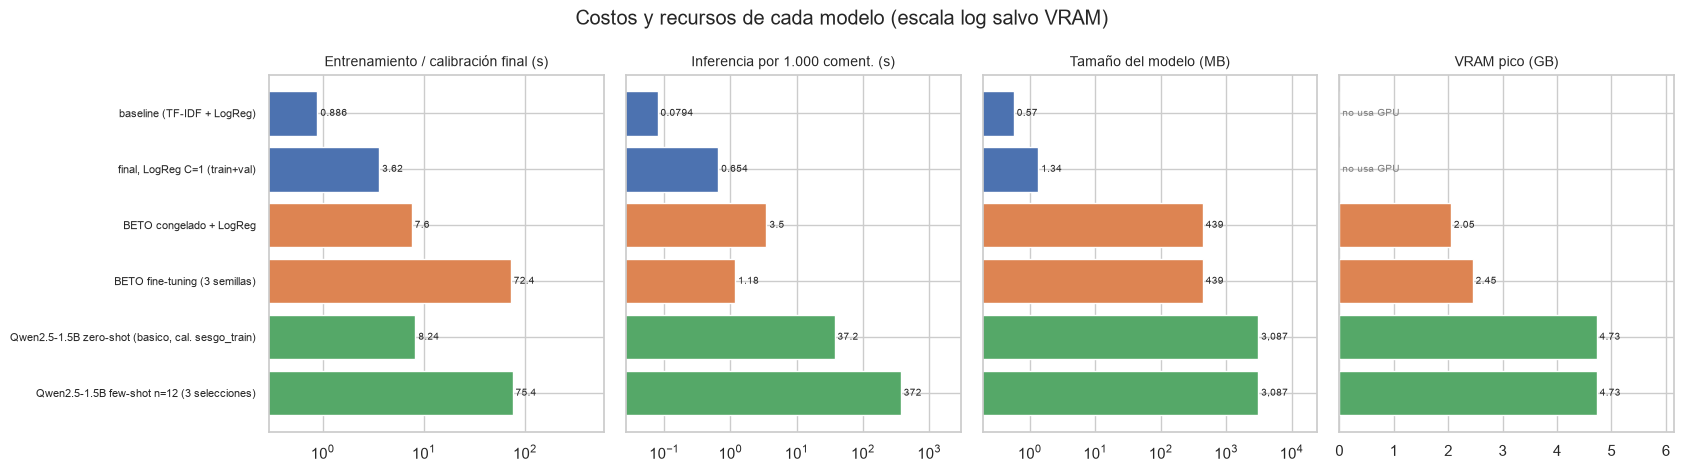

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(17, 0.55 * len(comp) + 1.5), sharey=True)
y_pos = np.arange(len(comp))
colores = [COLORES[e] for e in comp["enfoque"]]
for ax, col, titulo, log in [(axes[0], "t_train_s", "Entrenamiento / calibración final (s)", True),
                             (axes[1], "t_inf_por_1000_s", "Inferencia por 1.000 coment. (s)", True),
                             (axes[2], "tamaño_modelo_MB", "Tamaño del modelo (MB)", True),
                             (axes[3], "vram_pico_GB", "VRAM pico (GB)", False)]:
    valores = comp[col].fillna(0).to_numpy(dtype=float)
    ax.barh(y_pos, valores, color=colores)
    if log:
        ax.set_xscale("log")
        ax.set_xlim(valores[valores > 0].min() / 3, valores.max() * 8)
    else:
        ax.set_xlim(0, valores.max() * 1.3)
    for y, v in zip(y_pos, valores):
        if v > 0:
            ax.text(v, y, f" {v:,.0f}" if v >= 1000 else f" {v:.3g}", va="center", fontsize=7.5)
        else:
            ax.text(ax.get_xlim()[0], y, " no requiere" if col == "t_train_s" else " no usa GPU", va="center",
                    fontsize=7.5, color="gray")
    ax.set_title(titulo, fontsize=10)
axes[0].set_yticks(y_pos); axes[0].set_yticklabels([CORTO[m] for m in comp.index], fontsize=8)
axes[0].invert_yaxis()
plt.suptitle("Costos y recursos de cada modelo (escala log salvo VRAM)")
plt.tight_layout(); plt.show()

### 5.7. Desempeño según el acuerdo entre anotadores

En la parte 1 vimos que muchos comentarios tienen solo acuerdo parcial (2 de 3 anotadores). Si todos los modelos caen en esos comentarios, parte del error se explica por la ambigüedad de las etiquetas y no por el modelo: hay un techo de desempeño que ningún enfoque puede superar con estas etiquetas.

n por nivel: {'Total (3/3)': 216, 'Parcial (2/3)': 202}


nivel_acuerdo,Total (3/3),Parcial (2/3),caída
modelo,,,
Clásico: baseline (TF-IDF + LogReg),0.382,0.251,0.131
"Clásico: final, LogReg C=1 (train+val)",0.468,0.377,0.091
Encoder: BETO congelado + LogReg,0.481,0.406,0.075
Encoder: BETO fine-tuning (3 semillas),0.563,0.423,0.140
"LLM: Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)",0.515,0.508,0.007
LLM: Qwen2.5-1.5B few-shot n=12 (3 selecciones),0.536,0.486,0.050


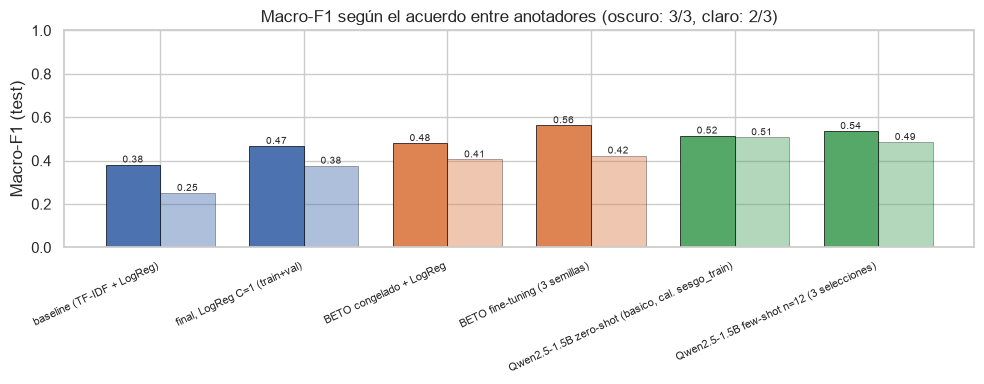

In [18]:
niveles = ["Total (3/3)", "Parcial (2/3)"]
filas_ac = []
for m, f in comp.iterrows():
    for nivel in niveles:
        mask = (test_df["nivel_acuerdo"] == nivel).to_numpy()
        mets = pd.DataFrame([metricas(y_test[mask], preds[c].to_numpy()[mask]) for c in f["cols_pred"]]).mean()
        filas_ac.append({"modelo": m, "enfoque": f["enfoque"], "nivel_acuerdo": nivel, "n": mask.sum(),
                         "macro_f1": mets["macro_f1"], "accuracy": mets["accuracy"]})
acuerdo = pd.DataFrame(filas_ac)
tabla_ac = acuerdo.pivot(index="modelo", columns="nivel_acuerdo", values="macro_f1").reindex(comp.index)[niveles]
tabla_ac["caída"] = tabla_ac[niveles[0]] - tabla_ac[niveles[1]]
print("n por nivel:", acuerdo.drop_duplicates("nivel_acuerdo").set_index("nivel_acuerdo")["n"].to_dict())
display(tabla_ac.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(comp))
for j, (nivel, tono) in enumerate(zip(niveles, [1.0, 0.45])):
    barras = ax.bar(x + (j - 0.5) * 0.38, tabla_ac[nivel], 0.38, label=nivel,
                    color=[COLORES[e] for e in comp["enfoque"]], alpha=tono, edgecolor="black", linewidth=0.5)
    ax.bar_label(barras, fmt="%.2f", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels([CORTO[m] for m in comp.index], rotation=25, ha="right", fontsize=8)
ax.set_ylabel("Macro-F1 (test)"); ax.set_ylim(0, 1)
ax.set_title("Macro-F1 según el acuerdo entre anotadores (oscuro: 3/3, claro: 2/3)")
plt.tight_layout(); plt.show()

### 5.8. ¿Los enfoques se equivocan en los mismos comentarios?

Si los distintos enfoques fallan en comentarios diferentes, cada uno captura información distinta (y combinarlos podría ayudar). Si fallan en los mismos, el límite está en los datos más que en el modelo. Se analiza:

- **Acuerdo entre modelos** (kappa de Cohen entre sus predicciones; para modelos con varias corridas, promedio sobre todos los pares de corridas).
- **Comentarios difíciles:** cuántos modelos aciertan cada comentario, y si los que nadie acierta son los de acuerdo parcial entre anotadores.

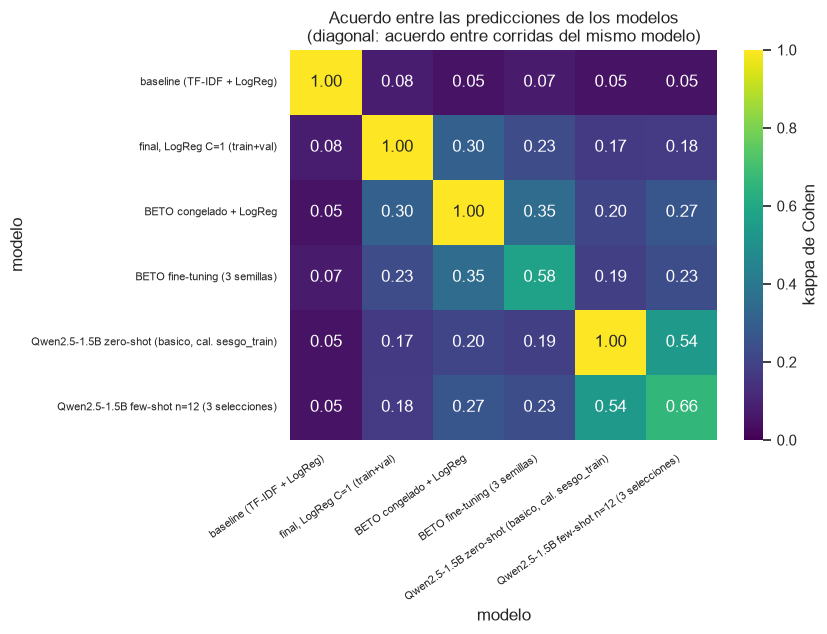

In [19]:
def kappa_medio(cols_a, cols_b):
    return np.mean([cohen_kappa_score(preds[a], preds[b]) for a in cols_a for b in cols_b if a != b])

kappas = pd.DataFrame(index=comp.index, columns=comp.index, dtype=float)
for a in comp.index:
    for b in comp.index:
        kappas.loc[a, b] = kappa_medio(comp.loc[a, "cols_pred"], comp.loc[b, "cols_pred"]) \
            if (a != b or len(comp.loc[a, "cols_pred"]) > 1) else 1.0

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(kappas, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax,
            xticklabels=[CORTO[m] for m in comp.index], yticklabels=[CORTO[m] for m in comp.index], cbar_kws={"label": "kappa de Cohen"})
ax.set_title("Acuerdo entre las predicciones de los modelos\n(diagonal: acuerdo entre corridas del mismo modelo)")
plt.xticks(rotation=35, ha="right", fontsize=8); plt.yticks(fontsize=8); ax.grid(False)
plt.tight_layout(); plt.show()

In [20]:
# Para cada comentario: fracción de corridas de cada modelo que lo aciertan (se excluye el baseline clásico,
# que es una referencia, y se usa un "voto" por modelo)
modelos_err = [m for m in comp.index if m != comp.index[0]]
aciertos = pd.DataFrame({m: np.mean([(preds[c].to_numpy() == y_test) for c in comp.loc[m, "cols_pred"]], axis=0)
                         for m in modelos_err}, index=test_df.index)
n_aciertan = (aciertos >= 0.5).sum(axis=1)

resumen = pd.DataFrame({"comentarios": n_aciertan.value_counts().sort_index(),
                        "% del test": n_aciertan.value_counts(normalize=True).sort_index() * 100})
resumen.index.name = f"modelos que aciertan (de {len(modelos_err)})"
display(resumen.round(1))

nadie = n_aciertan == 0
print(f"Comentarios que ningún modelo acierta: {nadie.sum()} ({nadie.mean():.1%})")
print(f"Comentarios que al menos un modelo acierta ('oráculo'): {(~nadie).mean():.1%} de accuracy máxima alcanzable "
      f"combinando los modelos perfectamente.")

dificiles = pd.DataFrame({
    "% acuerdo parcial (2/3)": [(test_df.loc[nadie, "nivel_acuerdo"] == "Parcial (2/3)").mean() * 100,
                                (test_df.loc[~nadie, "nivel_acuerdo"] == "Parcial (2/3)").mean() * 100],
    **{f"% {c}": [(test_df.loc[nadie, "label"] == c).mean() * 100, (test_df.loc[~nadie, "label"] == c).mean() * 100]
       for c in CLASES},
}, index=["Ningún modelo acierta", "Al menos uno acierta"])
display(dificiles.round(1))

,comentarios,% del test
modelos que aciertan (de 5),,
0,43,10.3
1,54,12.9
2,78,18.7
3,78,18.7
4,83,19.9
5,82,19.6


Comentarios que ningún modelo acierta: 43 (10.3%)
Comentarios que al menos un modelo acierta ('oráculo'): 89.7% de accuracy máxima alcanzable combinando los modelos perfectamente.


,% acuerdo parcial (2/3),% favor,% against,% neutral
Ningún modelo acierta,76.7,23.3,34.9,41.9
Al menos uno acierta,45.1,65.9,21.3,12.8


In [21]:
print("Ejemplos de comentarios que ningún modelo acierta:\n")
for _, fila in test_df[nadie].sample(min(6, nadie.sum()), random_state=SEED).iterrows():
    print(f"• [{fila['target'][:60]}] {fila['comment'][:250]}")
    print(f"  Etiqueta: {fila['label']} | Anotaciones: {fila[cols_anotadores].tolist()}\n")

Ejemplos de comentarios que ningún modelo acierta:

• [Reprobación de Esperanza Aguirre como concejala del Ayuntami] Por supuestísimo que esta señorona, no puede representar a nadie. Ni a ella misma, corre el riesgo de que se robe y lo done al PP. (bueno un parte claro).
Hay un refrán muy español que dice: "A todo cerdo/a, le llega su SanMartín".
  Etiqueta: favor | Anotaciones: ['favor', 'favor', 'against']

• [Nuevo protocolo contra la alta contaminación y Madrid Centra] La alta contaminacion se puede disminuir con menos atascos menos semaforos , se pueden encontrar semaforo a 20 30 metros de de distancia uno de otro y dos o pasos de peatones pues es mejor cerar la calle y hacerlo peatonal y no olvidemos de autobuses
  Etiqueta: neutral | Anotaciones: ['favor', 'neutral', 'neutral']

• [Nuevo protocolo contra la alta contaminación y Madrid Centra] Yo propongo su derogación inmediata, sobretodo de la velocidad, la de Madrid Central y todas las aprs clasistas y discriminadoras, la zona

### 5.9. Resumen de ventajas y desventajas

Se resume, para el mejor modelo de cada enfoque, el desempeño y los costos relativos al modelo clásico final, que es el más barato.

In [22]:
ref_clasico = comp.loc[mejor_por_enfoque["Clásico"]]
resumen_enfoques = []
for e, m in mejor_por_enfoque.items():
    f = comp.loc[m]
    resumen_enfoques.append({
        "enfoque": e, "modelo": m.split(": ", 1)[1],
        "Macro-F1 test": f"{f['macro_f1']:.3f}" + (f" ± {f['macro_f1_desvio_corridas']:.3f}"
                                                   if not np.isnan(f["macro_f1_desvio_corridas"]) else ""),
        "IC 95%": f"[{comp_total.loc[m, 'ic95_inf']:.3f}, {comp_total.loc[m, 'ic95_sup']:.3f}]",
        "Δ Macro-F1 vs. clásico": f"{f['macro_f1'] - ref_clasico['macro_f1']:+.3f}",
        "P(mejor que clásico)": "—" if m == ref_clasico.name else f"{(BOOT[m] > BOOT[ref_clasico.name]).mean():.2f}",
        "inferencia (× clásico)": f"{f['t_inf_por_1000_s'] / ref_clasico['t_inf_por_1000_s']:.0f}×",
        "tamaño (× clásico)": f"{f['tamaño_modelo_MB'] / ref_clasico['tamaño_modelo_MB']:.0f}×",
        "entrenamiento final": "no requiere" if f["t_train_s"] == 0 else
                               f"{f['t_train_s']:.0f} s" + (" (calibración)" if e == "LLM" else ""),
        "requiere GPU": "No" if f["hardware"] == "CPU" else "Sí",
        "datos etiquetados": "train completo (+ val para elegir)" if e != "LLM" else
                             "200 de train para calibrar (+ val para elegir)",
    })
display(pd.DataFrame(resumen_enfoques).set_index("enfoque"))

,modelo,Macro-F1 test,IC 95%,Δ Macro-F1 vs. clásico,P(mejor que clásico),inferencia (× clásico),tamaño (× clásico),entrenamiento final,requiere GPU,datos etiquetados
enfoque,,,,,,,,,,
Clásico,"final, LogReg C=1 (train+val)",0.435,"[0.384, 0.487]",+0.000,—,1×,1×,4 s,No,train completo (+ val para elegir)
Encoder,BETO fine-tuning (3 semillas),0.495 ± 0.017,"[0.453, 0.541]",+0.061,0.98,2×,328×,72 s,Sí,train completo (+ val para elegir)
LLM,"Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)",0.537,"[0.484, 0.588]",+0.102,1.00,57×,2303×,8 s (calibración),Sí,200 de train para calibrar (+ val para elegir)


| | **Clásico** (TF-IDF + LogReg) | **Encoder** (BETO) | **LLM** (Qwen2.5-1.5B con prompting) |
|---|---|---|---|
| **Ventajas** | Entrena en segundos y predice en milisegundos en CPU; modelo de ≈1 MB; interpretable (coeficientes por término); fácil de reentrenar | Inferencia rápida en GPU una vez entrenado (≈1 s cada 1.000 comentarios); con *fine-tuning* es el mejor en los comentarios con acuerdo total | Mejor Macro-F1 y mejor F1 en *neutral* sin ajustar pesos; casi no empeora en los comentarios ambiguos; se adapta cambiando el prompt; necesita muy pocos datos etiquetados (200 para calibrar) |
| **Desventajas** | Bolsa de palabras: no capta negaciones complejas ni la relación con la propuesta; *neutral* muy difícil | Requiere GPU para entrenar; ≈440 MB; sensible a la semilla; necesita el train completo etiquetado | Inferencia ≈30 veces más lenta que BETO (≈300 con *few-shot*); ≈3 GB de pesos y ≈4,7 GB de VRAM aunque sea un modelo chico; sin calibración rinde bastante peor; muy sensible a la instrucción y a los ejemplos |
| **Conviene cuando** | Hay pocos recursos, grandes volúmenes o se necesita una línea de base rápida e interpretable | Hay datos etiquetados y GPU para entrenar, y el modelo se va a usar sobre grandes volúmenes | Hay pocos datos etiquetados, se necesita un prototipo rápido o la tarea cambia seguido, y el volumen a clasificar es moderado |

### 5.10. Conclusiones

**¿Cuándo conviene utilizar técnicas tradicionales de ML, modelos preentrenados o LLMs para esta tarea?**

- **Desempeño.** Todos los enfoques superan claramente a la referencia trivial (Macro-F1 = 0,25 prediciendo siempre *favor*) y al baseline sin balancear (0,31), pero ninguno llega a 0,55. El mejor resultado es el del LLM en zero-shot con calibración (0,537), seguido por el LLM few-shot (0,530 ± 0,018), BETO con *fine-tuning* (0,495 ± 0,017), BETO congelado (0,458) y el modelo clásico final (0,435). Con 418 comentarios de test, los intervalos de confianza por bootstrap tienen un ancho de ≈±0,05 (sección 5.4): el LLM y BETO con *fine-tuning* superan al clásico final de forma significativa (+0,10 y +0,06), pero la diferencia entre el LLM y BETO con *fine-tuning* (+0,04, IC 95% [−0,02; +0,10]) no es concluyente.
- **Dónde gana cada uno.** La ventaja del LLM viene casi toda de la clase *neutral* (F1 0,40 contra 0,29 de BETO con *fine-tuning*) y de los comentarios con acuerdo parcial entre anotadores, donde casi no pierde desempeño (0,515 → 0,508). BETO con *fine-tuning* es el mejor en los comentarios con acuerdo total (0,563), pero cae 0,14 en los ambiguos (sección 5.7).
- **Costos.** Las diferencias de costo son mucho más grandes que las de desempeño. El modelo clásico entrena en segundos y clasifica 1.000 comentarios en menos de un segundo en CPU, con un modelo de ≈1 MB. BETO necesita GPU, ≈1 minuto de entrenamiento por corrida (≈16 minutos contando la exploración) y pesa ≈440 MB. El LLM no se entrena (solo ≈8 s de calibración), pero es ≈30 veces más lento que BETO en inferencia en la misma GPU (≈37 s cada 1.000 comentarios: ≈10 h para un millón), pesa ≈3 GB y usa ≈4,7 GB de VRAM. Su exploración de prompts y calibraciones también fue la más cara (≈24 minutos de GPU).
- **Few-shot no mejora.** Agregar 12 ejemplos al prompt no mejoró al zero-shot (−0,007, IC 95% [−0,05; +0,04]), hizo la inferencia ≈10 veces más lenta por el largo del prompt (≈1.700 tokens contra ≈190) y volvió los resultados dependientes de qué ejemplos se eligen.
- **La calibración fue decisiva para el LLM.** En validación, el prompt elegido pasó de 0,449 sin calibrar a 0,546 calibrado con `sesgo_train`, y en promedio las configuraciones calibradas así rindieron ≈0,05 (zero-shot) y ≈0,13 (few-shot) más que sin calibrar. Ajustar dos sesgos con 200 comentarios de train es lo que lo vuelve competitivo con BETO. Por eso el LLM tampoco es estrictamente "sin datos": necesita un conjunto chico de ejemplos etiquetados.
- **El límite está en parte en los datos.** Un 10% de los comentarios de test no lo acierta ningún modelo, y tres de cada cuatro de ellos tienen acuerdo parcial entre anotadores (sección 5.8). *neutral* es la clase más difícil para todos. Además, los enfoques se equivocan en comentarios bastante distintos (kappa entre enfoques de 0,2 a 0,35): combinando perfectamente sus predicciones se acertaría ≈90% del test, lo que sugiere que un ensamble podría mejorar los resultados.

**Recomendación:**
- **ML tradicional** cuando el volumen es muy grande, los recursos son limitados o se necesita interpretabilidad. Es la primera línea de base obligatoria: con balanceo de clases ya captura buena parte del desempeño alcanzable, a un costo ínfimo.
- **Encoder con fine-tuning** cuando hay datos etiquetados (≈2.000 comentarios alcanzaron) y una GPU para entrenar, y el modelo se va a usar sobre grandes volúmenes: rinde casi como el LLM y su inferencia es ≈30 veces más barata.
- **LLM con prompting** cuando hay pocos datos etiquetados, se necesita un prototipo inmediato o la tarea cambia seguido, y el volumen a clasificar es moderado. En este caso dio el mejor desempeño y es el más robusto ante comentarios ambiguos, a cambio de la inferencia más cara. Conviene calibrarlo y usar zero-shot: los ejemplos *few-shot* multiplicaron el costo sin mejorar el resultado.

**Reflexión del grupo.** *(Completar.)*